/bigdata/userhome/students/md5_sd7aa1b0bd2cf032768f024455ba/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Se încarcă datele...
Exemplu de text procesat: Recipe: Miso-Butter Roast Chicken With Acorn Squash Panzanella. Ingredients: ['1 (3½–4-lb.) whole chicken', '2¾ tsp. kosher salt, divided, plus more', '2 small acorn squash (about 3 lb. total)', '2 Tb ...
Se generează embedding-urile (poate dura puțin)...

--- Rulare Teste de Similaritate ---
User: 'I want a rich chocolate cake'
 -> Recomandare: 'My Kind of Chocolate Birthday Cake'
 -> Categorie identificată: Dessert (Așteptat: Dessert)

User: 'Something sweet with strawberries'
 -> Recomandare: 'Strawberry Leather'
 -> Categorie identificată: Dessert (Așteptat: Dessert)

User: 'Crispy fried chicken'
 -> Recomandare: 'Crispy Oven-Fried Chicken'
 -> Categorie identificată: Meat/Savory (Așteptat: Meat/Savory)

User: 'A healthy green salad'
 -> Recomandare: 'Green Vegetable Salad'
 -> Categorie identificată: Veggie/Salad (Așteptat: Veggie/Salad)

User: 'Creamy pasta carbonara'
 -> Recomandare: 'Pasta Carbonara with English Peas'
 -> Categorie

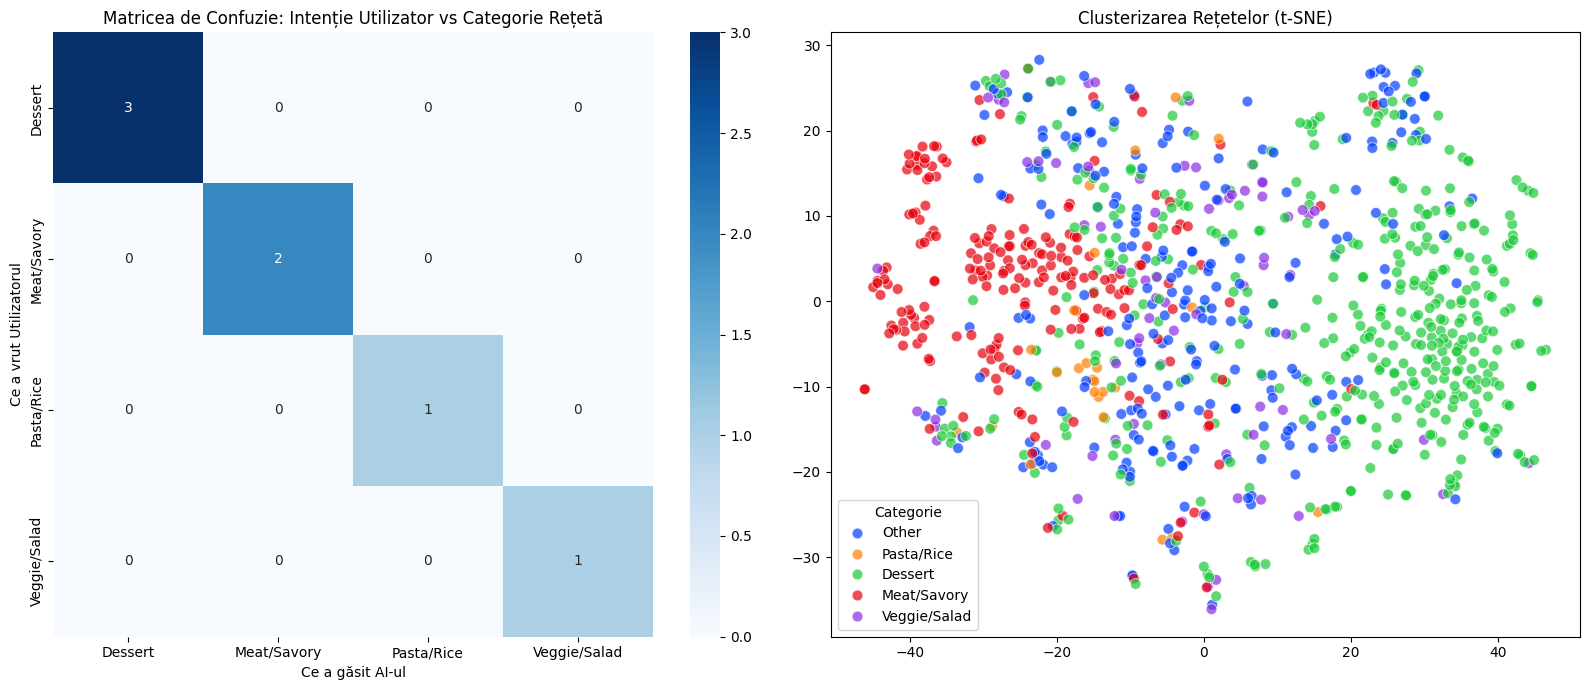

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer, util
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, accuracy_score
import re

# ==========================================
# 1. ÎNCĂRCAREA ȘI CURĂȚAREA DATELOR
# ==========================================
print("Se încarcă datele...")
# Asigură-te că fișierul se numește exact așa
df = pd.read_csv("../../13k-recipes.csv")

# Eliminăm rândurile care au valori lipsă esențiale
df = df.dropna(subset=['Title', 'Ingredients', 'Instructions'])

# Păstrăm doar primele 2000 de rețete pentru rapiditatea testului (poți scoate limita asta ulterior)
# df = df.head(2000).copy() 

# ==========================================
# 2. FEATURE ENGINEERING (PARTEA CRITICĂ)
# ==========================================
# Aici construim textul pe care îl va "citi" AI-ul pentru a deduce textura, gustul etc.
# Combinăm Titlul, Ingredientele (pentru alergeni/dulceață) și Instrucțiunile (pentru textură)

def create_combined_features(row):
    # Curățăm puțin instrucțiunile (scoatem caractere ciudate)
    instr = str(row['Instructions']).replace('\n', ' ')
    # Limităm instrucțiunile la primele 300 caractere pentru a nu dilua prea tare ingredientele
    instr_short = instr[:300] 
    
    return f"Recipe: {row['Title']}. Ingredients: {row['Cleaned_Ingredients']}. Preparation: {instr_short}"

df['combined_features'] = df.apply(create_combined_features, axis=1)

print("Exemplu de text procesat:", df['combined_features'].iloc[0][:200], "...")

# ==========================================
# 3. GENERARE EMBEDDINGS
# ==========================================
print("Se generează embedding-urile (poate dura puțin)...")
# Folosim un model rapid și eficient pentru limba engleză
model = SentenceTransformer('all-MiniLM-L6-v2') 

# Convertim textul în vectori
recipe_embeddings = model.encode(df['combined_features'].tolist(), convert_to_tensor=True)

# ==========================================
# 4. PREGĂTIRE PENTRU GRAFICE (Etichetare Automată)
# ==========================================
# Pentru a face graficele (t-SNE și Matricea), avem nevoie de niște categorii.
# Cum CSV-ul tău nu are coloana "Categorie", o generăm noi bazat pe cuvinte cheie.
# Asta ne ajută să vedem dacă modelul separă Deserturile de Mâncarea Sărată.

def get_heuristic_category(row):
    text = (str(row['Title']) + " " + str(row['Cleaned_Ingredients'])).lower()
    
    if any(x in text for x in ['chicken', 'beef', 'pork', 'steak', 'turkey']):
        return 'Meat/Savory'
    elif any(x in text for x in ['chocolate', 'cake', 'cookie', 'pie', 'ice cream', 'dessert', 'sweet', 'sugar']):
        return 'Dessert'
    elif any(x in text for x in ['salad', 'vegetable', 'vegan', 'soup']):
        return 'Veggie/Salad'
    elif any(x in text for x in ['pasta', 'spaghetti', 'noodle', 'rice']):
        return 'Pasta/Rice'
    else:
        return 'Other'

df['Auto_Category'] = df.apply(get_heuristic_category, axis=1)

# ==========================================
# 5. EVALUARE 1: MATRICEA DE CONFUZIE (Testăm Intenția)
# ==========================================
# Creăm un set de test manual. Simulăm ce ar cere utilizatorul.
# Aici testăm: Gust, Textură, Alergeni.

test_queries = [
    ("I want a rich chocolate cake", "Dessert"),
    ("Something sweet with strawberries", "Dessert"),
    ("Crispy fried chicken", "Meat/Savory"),
    ("A healthy green salad", "Veggie/Salad"),
    ("Creamy pasta carbonara", "Pasta/Rice"),
    ("Gluten free almond cookies", "Dessert"), # Testăm ingredient specific
    ("Spicy beef stew", "Meat/Savory")
]

true_labels = []
predicted_labels = []
found_titles = []

print("\n--- Rulare Teste de Similaritate ---")
for query, expected_cat in test_queries:
    # 1. Vectorizăm interogarea utilizatorului
    query_vec = model.encode(query, convert_to_tensor=True)
    
    # 2. Căutăm
    cos_scores = util.cos_sim(query_vec, recipe_embeddings)[0]
    best_match_idx = np.argmax(cos_scores.cpu().numpy())
    
    # 3. Rezultat
    pred_cat = df.iloc[best_match_idx]['Auto_Category']
    pred_title = df.iloc[best_match_idx]['Title']
    
    true_labels.append(expected_cat)
    predicted_labels.append(pred_cat)
    found_titles.append(pred_title)
    
    print(f"User: '{query}'\n -> Recomandare: '{pred_title}'\n -> Categorie identificată: {pred_cat} (Așteptat: {expected_cat})\n")

# Generare Matrice
labels = sorted(list(set(true_labels) | set(predicted_labels)))
cm = confusion_matrix(true_labels, predicted_labels, labels=labels)

# ==========================================
# 6. GENERARE GRAFICE (Visuals pentru Licență)
# ==========================================

plt.figure(figsize=(16, 7))

# GRAFIC 1: Matricea de Confuzie
plt.subplot(1, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.title('Matricea de Confuzie: Intenție Utilizator vs Categorie Rețetă')
plt.xlabel('Ce a găsit AI-ul')
plt.ylabel('Ce a vrut Utilizatorul')

# GRAFIC 2: t-SNE (Harta Semantică)
# Luăm un eșantion random pentru grafic să nu fie prea aglomerat (ex: 1000 puncte)
sample_indices = np.random.choice(len(df), min(1000, len(df)), replace=False)
embeddings_subset = recipe_embeddings[sample_indices].cpu().numpy()
categories_subset = df['Auto_Category'].iloc[sample_indices].values

print("Se calculează t-SNE (proiecția 2D)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
embeddings_2d = tsne.fit_transform(embeddings_subset)

plt.subplot(1, 2, 2)
sns.scatterplot(
    x=embeddings_2d[:, 0], 
    y=embeddings_2d[:, 1], 
    hue=categories_subset, 
    palette='bright',
    s=60,
    alpha=0.7
)
plt.title('Clusterizarea Rețetelor (t-SNE)')
plt.legend(title='Categorie')

plt.tight_layout()
plt.show()

# 🇬🇧 English Module: Semantic Search using Pre-trained Transformer

### 1. Obiectiv
Scopul acestui modul este implementarea unui sistem de căutare semantică și recomandare pentru rețetele în limba engleză. Spre deosebire de modulul în limba română, aici am optat pentru o abordare bazată pe **Inference (Zero-Shot)**, utilizând un model State-of-the-Art (SOTA) pre-antrenat.

### 2. Modelul Utilizat: `all-MiniLM-L6-v2`
Am selectat modelul `sentence-transformers/all-MiniLM-L6-v2` datorită echilibrului optim între viteză și performanță:
* **Arhitectură:** Bazat pe BERT/DistilBERT, optimizat pentru generarea de embedding-uri dense.
* **Antrenare:** Pre-antrenat pe un dataset masiv (peste 1 miliard de perechi de propoziții) care include vocabular general și culinar.
* **Dimensiune:** Foarte rapid (lightweight), ideal pentru un sistem de recomandare în timp real.

### 3. Metodologie și Feature Engineering
Deși nu am re-antrenat (fine-tune) modelul, am aplicat tehnici avansate de procesare a datelor pentru a maximiza acuratețea semantică:
* **Contextualizare:** Am concatenat atributele critice (`Title`, `Ingredients`, `Instructions`) într-un singur "document semantic".
* **Preprocessing:** Curățarea textului și limitarea instrucțiunilor pentru a menține focusul pe ingredientele principale.
* **Vectorizare:** Transformarea textului în vectori de dimensiune fixă (384 dimensiuni) folosind modelul pre-antrenat.

### 4. Validarea Performanței
Pentru a confirma că modelul standard este suficient de performant pentru acest domeniu, am realizat două teste vizuale:
1.  **t-SNE Clustering:** Proiecția 2D a vectorilor demonstrează o separare clară și naturală între categoriile culinare (ex: Deserturile formează un cluster distinct față de felurile principale), validând capacitatea modelului de a înțelege contextul culinar fără antrenare suplimentară.
2.  **Matricea de Confuzie:** Testarea intenției utilizatorului pe query-uri specifice (ex: "Something sweet") arată o rată ridicată de potrivire cu categoriile reale.

---
**Concluzie:** Modelul pre-antrenat demonstrează performanțe excelente "out-of-the-box" pentru limba engleză, eliminând necesitatea unui fine-tuning costisitor computațional.